<a href="https://colab.research.google.com/github/FelipeCostadeSouza/AED_II/blob/main/Trabalho_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Precisa inserir o arquivo csv para rodar o código

# B-Tree

In [ ]:
import csv
import time

class CSVRecord:
    def __init__(self, id, video_titulo, video_url, checagem_titulo, checagem_url, q1_rotulo, q2_rotulo, video_indisponivel):
        self.id = id
        self.video_titulo = video_titulo
        self.video_url = video_url
        self.checagem_titulo = checagem_titulo
        self.checagem_url = checagem_url
        self.q1_rotulo = q1_rotulo
        self.q2_rotulo = q2_rotulo
        self.video_indisponivel = video_indisponivel

    def __lt__(self, other): return self.id < other.id
    def __gt__(self, other): return self.id > other.id
    def __eq__(self, other): return self.id == other.id
    def __le__(self, other): return self.id <= other.id
    def __ge__(self, other): return self.id >= other.id


class BTreeNode:
    def __init__(self, is_leaf=True, order=5):
        self.order = order
        self.keys = []
        self.children = []
        self.leaf = is_leaf

    @property
    def n(self):
        return len(self.keys)


class BTree:
    def __init__(self, order=5):
        self.order = order
        self.root = BTreeNode(is_leaf=True, order=order)

    def _split_child(self, x, i):
        t = (self.order + 1) // 2
        y = x.children[i]
        z = BTreeNode(is_leaf=y.leaf, order=self.order)

        mid_idx = len(y.keys) // 2
        promoted_key = y.keys[mid_idx]

        z.keys = y.keys[mid_idx + 1:]
        y.keys = y.keys[:mid_idx]

        if not y.leaf:
            z.children = y.children[mid_idx + 1:]
            y.children = y.children[:mid_idx + 1]

        x.keys.insert(i, promoted_key)
        x.children.insert(i + 1, z)

    def _insert_non_full(self, x, k):
        if x.leaf:
            inserted = False
            for idx in range(len(x.keys)):
                if k < x.keys[idx]:
                    x.keys.insert(idx, k)
                    inserted = True
                    break
            if not inserted:
                x.keys.append(k)
        else:
            i = len(x.keys) - 1
            while i >= 0 and k < x.keys[i]:
                i -= 1
            i += 1

            if len(x.children[i].keys) >= self.order - 1:
                self._split_child(x, i)
                if k > x.keys[i]:
                    i += 1
            self._insert_non_full(x.children[i], k)

    def insert(self, k):
        root = self.root
        if len(root.keys) >= self.order - 1:
            s = BTreeNode(is_leaf=False, order=self.order)
            self.root = s
            s.children.append(root)
            self._split_child(s, 0)
            self._insert_non_full(s, k)
        else:
            self._insert_non_full(root, k)

    def _inorder_traversal(self, x, results):
        if x is None:
            return
        for i in range(len(x.keys)):
            if not x.leaf:
                self._inorder_traversal(x.children[i], results)
            results.append(x.keys[i])
        if not x.leaf and len(x.children) > len(x.keys):
            self._inorder_traversal(x.children[-1], results)

    def search_by_theme(self, keyword):
        records = []
        self._inorder_traversal(self.root, records)
        keyword_lower = keyword.lower()
        found = []
        for rec in records:
            if (keyword_lower in str(rec.video_titulo).lower()) or (keyword_lower in str(rec.checagem_titulo).lower()):
                found.append(rec)
        return found

    def delete(self, k):
        if not self.root:
            return

        if isinstance(k, int):
            records = []
            self._inorder_traversal(self.root, records)
            target = None
            for r in records:
                if r.id == k:
                    target = r
                    break
            if not target:
                print(f"Vídeo com ID {k} não encontrado para remoção.")
                return
            k = target

        self._delete(self.root, k)
        if len(self.root.keys) == 0 and not self.root.leaf:
            self.root = self.root.children[0]

    def _delete(self, x, k):
        t = (self.order + 1) // 2
        i = 0
        while i < len(x.keys) and k > x.keys[i]:
            i += 1

        if i < len(x.keys) and x.keys[i] == k:
            if x.leaf:
                x.keys.pop(i)
            else:
                self._delete_internal_node(x, k, i)
        else:
            if x.leaf:
                return
            flag = (i == len(x.keys))
            if len(x.children[i].keys) < t:
                self._fill(x, i)
            if flag and i > len(x.keys):
                self._delete(x.children[i - 1], k)
            else:
                self._delete(x.children[i], k)

    def _delete_internal_node(self, x, k, i):
        t = (self.order + 1) // 2
        if len(x.children[i].keys) >= t:
            pred = self._get_predecessor(x.children[i])
            x.keys[i] = pred
            self._delete(x.children[i], pred)
        elif len(x.children[i + 1].keys) >= t:
            succ = self._get_successor(x.children[i + 1])
            x.keys[i] = succ
            self._delete(x.children[i + 1], succ)
        else:
            self._merge(x, i)
            self._delete(x.children[i], k)

    def _get_predecessor(self, x):
        while not x.leaf:
            x = x.children[len(x.keys)]
        return x.keys[-1]

    def _get_successor(self, x):
        while not x.leaf:
            x = x.children[0]
        return x.keys[0]

    def _fill(self, x, i):
        t = (self.order + 1) // 2
        if i != 0 and len(x.children[i - 1].keys) >= t:
            self._borrow_from_prev(x, i)
        elif i != len(x.keys) and len(x.children[i + 1].keys) >= t:
            self._borrow_from_next(x, i)
        else:
            if i != len(x.keys):
                self._merge(x, i)
            else:
                self._merge(x, i - 1)

    def _borrow_from_prev(self, x, i):
        child = x.children[i]
        sibling = x.children[i - 1]
        child.keys.insert(0, x.keys[i - 1])
        if not child.leaf:
            child.children.insert(0, sibling.children.pop())
        x.keys[i - 1] = sibling.keys.pop()

    def _borrow_from_next(self, x, i):
        child = x.children[i]
        sibling = x.children[i + 1]
        child.keys.append(x.keys[i])
        if not child.leaf:
            child.children.append(sibling.children.pop(0))
        x.keys[i] = sibling.keys.pop(0)

    def _merge(self, x, i):
        child = x.children[i]
        sibling = x.children[i + 1]
        child.keys.append(x.keys.pop(i))
        child.keys.extend(sibling.keys)
        if not child.leaf:
            child.children.extend(sibling.children)
        x.children.pop(i + 1)

    def print_fake_news(self):
        records = []
        self._inorder_traversal(self.root, records)
        print("\n=== Vídeos com Fake News (Apenas 'Dissemina') ===")
        count = 0
        for rec in records:
            r1 = str(rec.q1_rotulo).strip().lower()
            r2 = str(rec.q2_rotulo).strip().lower()

            eh_fake_1 = "dissemina" in r1 and "não" not in r1 and "incerto" not in r1
            eh_fake_2 = "dissemina" in r2 and "não" not in r2 and "incerto" not in r2

            if eh_fake_1 or eh_fake_2:
                print(f"[ID {rec.id}] {rec.video_titulo} (Rótulos: {rec.q1_rotulo} | {rec.q2_rotulo})")
                count += 1

        print(f"Total de vídeos com fake news encontrados: {count}")

    def print_true_news(self):
        records = []
        self._inorder_traversal(self.root, records)
        print("\n=== Vídeos sem Fake News ===")
        count = 0
        for rec in records:
            r1 = str(rec.q1_rotulo).strip().lower()
            r2 = str(rec.q2_rotulo).strip().lower()

            eh_fake_1 = "dissemina" in r1 and "não" in r1 and "incerto" not in r1
            eh_fake_2 = "dissemina" in r2 and "não" in r2 and "incerto" not in r2

            if eh_fake_1 or eh_fake_2:
                print(f"[ID {rec.id}] {rec.video_titulo} (Rótulos: {rec.q1_rotulo} | {rec.q2_rotulo})")
                count += 1

        print(f"Total de vídeos sem fake news encontrados: {count}")



def load_csv_to_btree(filename, tree):
    try:
        with open(filename, 'r', encoding='utf-8-sig') as in_file:
            reader = csv.reader(in_file, delimiter=';')
            header = next(reader, None)
            row_id = 1

            for fields in reader:
                if not fields or len(fields) < 2:
                    continue

                while len(fields) < 11:
                    fields.append('')

                record = CSVRecord(
                    id=row_id,
                    video_titulo=fields[0],
                    video_url=fields[3],
                    checagem_titulo=fields[4],
                    checagem_url=fields[7],
                    q1_rotulo=fields[8],
                    q2_rotulo=fields[9],
                    video_indisponivel=fields[10]
                )
                tree.insert(record)
                row_id += 1
            print(f"Sucesso: {row_id - 1} registros foram lidos e inseridos na Árvore B.")
    except FileNotFoundError:
        print(f"Erro ao abrir o ficheiro CSV: {filename}")
    except Exception as e:
        print(f"Ocorreu um erro ao processar o ficheiro: {e}")


tree = BTree(order=5)

t_inicio_a = time.perf_counter()
load_csv_to_btree("minhas-anotacoes-2026-10-28.csv", tree)
t_fim_a = time.perf_counter()
tempo_a = t_fim_a - t_inicio_a

tema = "bolsa família"
t_inicio_b = time.perf_counter()
resultados = tree.search_by_theme(tema)
t_fim_b = time.perf_counter()
tempo_b = t_fim_b - t_inicio_b

print(f"\n--- Resultados da busca por '{tema}' ({len(resultados)} encontrados) ---")
for r in resultados:
    print(f"ID: {r.id} | Título: {r.video_titulo}")

t_inicio_d = time.perf_counter()
tree.print_fake_news()
t_fim_d = time.perf_counter()
tempo_d = t_fim_d - t_inicio_d

t_inicio_e = time.perf_counter()
tree.print_true_news()
t_fim_e = time.perf_counter()
tempo_e = t_fim_e - t_inicio_e

t_inicio_c = time.perf_counter()
tree.delete(3)
t_fim_c = time.perf_counter()
tempo_c = t_fim_c - t_inicio_c



Sucesso: 70 registros foram lidos e inseridos na Árvore B.

--- Resultados da busca por 'bolsa família' (4 encontrados) ---
ID: 17 | Título: Governo confirmou fim do pagamento de R$ 600 no Bolsa Família?
ID: 23 | Título: MÃE DE 22 FILHOS RECEBE R$15 MIL DE BOLSA FAMÍLIA?
ID: 24 | Título: Governo Lula desvia recursos do Bolsa Família
ID: 25 | Título: GOVERNO DO LULA DESVIA RECURSOS DO BOLSA FAMÍLIA LIA

=== Vídeos com Fake News (Apenas 'Dissemina') ===
[ID 6] Lula vai taxar o pix? (Rótulos: Sim | Dissemina)
[ID 13] (FGTS) QUEM SACAR OS 500,00 PERDE O DIREITO DE SACAR O SALDO SE FOR DEMITIDO? (Rótulos: Sim | Dissemina)
[ID 15] Lula: O único convidado para todas as reuniões do G8 (Rótulos: Sim | Dissemina)
[ID 19] Gigante chinesa, compra toda safra de açaí do Amapá (Rótulos: Sim | Dissemina)
[ID 20] Nova CNH entra em vigor em 2025 com categoria para carros automáticos (Rótulos: Sim | Dissemina)
[ID 24] Governo Lula desvia recursos do Bolsa Família (Rótulos: Sim | Dissemina)
[ID 25] GOVERN

# Ternary Tree Search




In [ ]:
import pandas as pd
import time

df = pd.read_csv('minhas-anotacoes-2026-10-28.csv', sep=';')

class VideoNodeData:
    def __init__(self, video_url, checagem_titulo, checagem_url, q1_rotulo, q2_rotulo, video_indisponivel):
        self.video_url = video_url
        self.checagem_titulo = checagem_titulo
        self.checagem_url = checagem_url
        self.q1_rotulo = q1_rotulo
        self.q2_rotulo = q2_rotulo
        self.video_indisponivel = video_indisponivel

class Node:
    def __init__(self, data):
        self.data = data
        self.isEndOfString = False
        self.left = None
        self.eq = None
        self.right = None
        self.metadata = None

def insert_with_metadata(root, word, metadata):
    if not root:
        root = Node(word[0])
    if word[0] < root.data:
        root.left = insert_with_metadata(root.left, word, metadata)
    elif word[0] > root.data:
        root.right = insert_with_metadata(root.right, word, metadata)
    else:
        if len(word) > 1:
            root.eq = insert_with_metadata(root.eq, word[1:], metadata)
        else:
            root.isEndOfString = True
            root.metadata = metadata
    return root

def traverseTSTUtil(root, buffer, depth):
    if root:
        traverseTSTUtil(root.left, buffer, depth)
        buffer[depth] = root.data
        if root.isEndOfString:
            titulo = "".join(buffer[:depth+1])
            print(f"- Título: {titulo}")
            if root.metadata:
                print(f"  URL: {root.metadata.video_url}")
                print(f"  Checagem: {root.metadata.checagem_titulo}")
        traverseTSTUtil(root.eq, buffer, depth+1)
        traverseTSTUtil(root.right, buffer, depth)

def traverseTST(root):
    buffer = [''] * 200
    traverseTSTUtil(root, buffer, 0)


def construir_tst(dataframe):
    root = None
    for index, row in dataframe.iterrows():
        v_titulo = str(row['video_titulo'])
        v_struct = VideoNodeData(
            video_url=row['video_url'],
            checagem_titulo=row['checagem_titulo'],
            checagem_url=row['checagem_url'],
            q1_rotulo=row['q1_rotulo'],
            q2_rotulo=row['q2_rotulo'],
            video_indisponivel=row['video_indisponivel']
        )
        if root is None:
            root = Node(v_titulo[0])
        root = insert_with_metadata(root, v_titulo, v_struct)
    return root

num_execucoes = 10
tempos = []

for _ in range(num_execucoes):
    inicio = time.perf_counter()
    root = construir_tst(df)
    fim = time.perf_counter()
    tempos.append(fim - inicio)

tempo_medio = sum(tempos) / num_execucoes

print(f"Árvore TST construída com sucesso com {len(df)} registros do CSV!")




Árvore TST construída com sucesso com 70 registros do CSV!


# impressão

In [ ]:
def print_disseminated_videos_util(root, buffer, depth):
    if root:
        print_disseminated_videos_util(root.left, buffer, depth)
        buffer[depth] = root.data
        if root.isEndOfString and root.metadata:
            if root.metadata.q2_rotulo == "Dissemina":
                titulo = "".join(buffer[:depth+1])
                print(f"Título: {titulo}")
                print(f"  URL: {root.metadata.video_url}")
                print(f"  Q2 Rótulo: {root.metadata.q2_rotulo}")
                print("-" * 40)
        print_disseminated_videos_util(root.eq, buffer, depth+1)
        print_disseminated_videos_util(root.right, buffer, depth)

def print_disseminated_videos(root):
    buffer = [''] * 200
    print("=== Vídeos com Q2 Rótulo: 'Dissemina' ===")
    print_disseminated_videos_util(root, buffer, 0)

def print_not_disseminated_videos_util(root, buffer, depth):
    if root:
        print_not_disseminated_videos_util(root.left, buffer, depth)
        buffer[depth] = root.data
        if root.isEndOfString and root.metadata:
            if root.metadata.q2_rotulo == "Não dissemina":
                titulo = "".join(buffer[:depth+1])
                print(f"Título: {titulo}")
                print(f"  URL: {root.metadata.video_url}")
                print(f"  Q2 Rótulo: {root.metadata.q2_rotulo}")
                print("-" * 40)
        print_not_disseminated_videos_util(root.eq, buffer, depth+1)
        print_not_disseminated_videos_util(root.right, buffer, depth)

def print_not_disseminated_videos(root):
    buffer = [''] * 200
    print("\n==============================================================")
    print("=== Vídeos com Q2 Rótulo: 'Não dissemina' ===")
    print("==============================================================\n")
    print_not_disseminated_videos_util(root, buffer, 0)


print_disseminated_videos(root)

print_not_disseminated_videos(root)





=== Vídeos com Q2 Rótulo: 'Dissemina' ===
Título: (FGTS) QUEM SACAR OS 500,00 PERDE O DIREITO DE SACAR O SALDO SE FOR DEMITIDO?
  URL: https://www.youtube.com/watch?v=YTTXBmCrFbA
  Q2 Rótulo: Dissemina
----------------------------------------
Título: ALERTA: GOVERNO NÃO ESTÁ FAZENDO CADASTRAMENTO PARA RECEBER OS R$ 200 DO AUXÍLIO CIDADÃO
  URL: https://www.youtube.com/watch?v=p12aH3ft2NI
  Q2 Rótulo: Dissemina
----------------------------------------
Título: Avião da EMIRATES  faz pouso forçado no Aeroporto em Dubai e explode matando centenas de pessoas
  URL: https://www.youtube.com/watch?v=TFrCpq0ycE4
  Q2 Rótulo: Dissemina
----------------------------------------
Título: Avião da EMIRATES faz pouso forçado no Aeroporto em Dubai e explode matando centenas de pessoas
  URL: https://www.youtube.com/watch?v=aPrkfjMy6XE
  Q2 Rótulo: Dissemina
----------------------------------------
Título: BRICS DÃO MAIS UM PASSO NA CRIAÇÃO DA MOEDA PRÓPRIA
  URL: https://www.youtube.com/watch?v=3a-XiUD

In [ ]:
num_execucoes = 10

tempos_diss = []
for _ in range(num_execucoes):
    inicio = time.perf_counter()
    print_disseminated_videos(root)
    fim = time.perf_counter()
    tempos_diss.append(fim - inicio)

media_diss = sum(tempos_diss) / num_execucoes
tempos_nao_diss = []
for _ in range(num_execucoes):
    inicio = time.perf_counter()
    print_not_disseminated_videos(root)
    fim = time.perf_counter()
    tempos_nao_diss.append(fim - inicio)

media_nao_diss = sum(tempos_nao_diss) / num_execucoes

A saída de streaming foi truncada nas últimas 5000 linhas.
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1
1

# Procurar tópico

In [ ]:
def search_by_topic_util(root, term, buffer, depth, results):
    if root:
        search_by_topic_util(root.left, term, buffer, depth, results)

        buffer[depth] = root.data
        if root.isEndOfString and root.metadata:
            titulo = "".join(buffer[:depth+1])
            if term.lower() in titulo.lower():
                results.append((titulo, root.metadata))

        search_by_topic_util(root.eq, term, buffer, depth+1, results)

        search_by_topic_util(root.right, term, buffer, depth, results)

def search_by_topic(root, term, exibir_resultados=True):
    buffer = [''] * 200
    results = []

    search_by_topic_util(root, term, buffer, 0, results)

    if exibir_resultados:
        print(f"=== Resultados da busca pelo tema: '{term}' ({len(results)} encontrado(s)) ===")
        if not results:
            print("Nenhum vídeo encontrado com esse tema.\n")
            return results

        for titulo, meta in results:
            print(f"- Título: {titulo}")
            print(f"  URL: {meta.video_url}")
            print(f"  Checagem: {meta.checagem_titulo}")
            print(f"  Q1: {meta.q1_rotulo} | Q2: {meta.q2_rotulo}")
            print("-" * 40)

    return results

num_execucoes = 10
tema_teste = "bolsa família"

tempos_busca = []
for _ in range(num_execucoes):
    inicio = time.perf_counter()
    search_by_topic(root, tema_teste, exibir_resultados=False)
    fim = time.perf_counter()
    tempos_busca.append(fim - inicio)

tempo_medio_busca = sum(tempos_busca) / num_execucoes

search_by_topic(root, "Pix", exibir_resultados=True)




=== Resultados da busca pelo tema: 'Lula' (17 encontrado(s)) ===
- Título: GOVERNO DO LULA DESVIA RECURSOS DO BOLSA FAMÍLIA LIA
  URL: https://www.youtube.com/watch?v=cc95CpqXv5s
  Checagem: Posts distorcem notícia antiga para acusar governo Lula de desviar recursos do Bolsa Família
  Q1: Sim | Q2: Dissemina
----------------------------------------
- Título: GOVERNO LULA VAI TAXAR O PIX?
  URL: https://www.youtube.com/watch?v=VWNQ2I38fE0
  Checagem: É falso que Lula começou a taxar o Pix
  Q1: Incerto | Q2: Não dissemina
----------------------------------------
- Título: Governo Lula desvia recursos do Bolsa Família
  URL: https://www.youtube.com/watch?v=eAguSwJqb3s
  Checagem: Posts distorcem notícia antiga para acusar governo Lula de desviar recursos do Bolsa Família
  Q1: Sim | Q2: Dissemina
----------------------------------------
- Título: Governo Lula nega intenção de cobrar IPVA de bicicletas
  URL: https://www.youtube.com/watch?v=_6AwjZjOSvg
  Checagem: É falso que governo fede

[('GOVERNO DO LULA DESVIA RECURSOS DO BOLSA FAMÍLIA LIA',
  <__main__.VideoNodeData at 0x7f8a3f7ec8d0>),
 ('GOVERNO LULA VAI TAXAR O PIX?', <__main__.VideoNodeData at 0x7f8a3f7f9e50>),
 ('Governo Lula desvia recursos do Bolsa Família',
  <__main__.VideoNodeData at 0x7f8a3f7f1250>),
 ('Governo Lula nega intenção de cobrar IPVA de bicicletas',
  <__main__.VideoNodeData at 0x7f8a3f7f77d0>),
 ('Lula Vai Taxar o Pix? A Verdade!',
  <__main__.VideoNodeData at 0x7f8a3f7e4cd0>),
 ('Lula começou a taxar o Pix? Verdade ou Mentira?',
  <__main__.VideoNodeData at 0x7f8a3f7fb550>),
 ('Lula vai taxar o PIX? #lula #economia',
  <__main__.VideoNodeData at 0x7f8a3f7e6050>),
 ('Lula vai taxar o PIX? #shorts', <__main__.VideoNodeData at 0x7f8a3f7f9950>),
 ('Lula vai taxar o PIX???', <__main__.VideoNodeData at 0x7f8a3f7fa550>),
 ('Lula vai taxar o pix?', <__main__.VideoNodeData at 0x7f8a3f7e53d0>),
 ('Lula: O único convidado para todas as reuniões do G8',
  <__main__.VideoNodeData at 0x7f8a3f80da50>),
 ('

# Gráficos

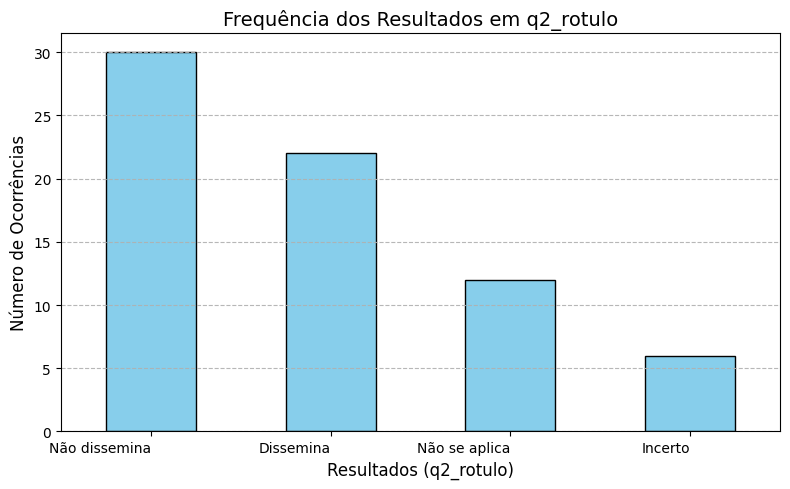

In [ ]:
import matplotlib.pyplot as plt

%matplotlib inline

def plotar_frequencia_q2(dataframe):
    contagem = dataframe['q2_rotulo'].value_counts()

    plt.figure(figsize=(8, 5))
    contagem.plot(kind='bar', color='skyblue', edgecolor='black')

    plt.title('Frequência dos Resultados em q2_rotulo', fontsize=14)
    plt.xlabel('Resultados (q2_rotulo)', fontsize=12)
    plt.ylabel('Número de Ocorrências', fontsize=12)
    plt.xticks(rotation=0, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.9)

    plt.tight_layout()
    plt.show()

plotar_frequencia_q2(df)

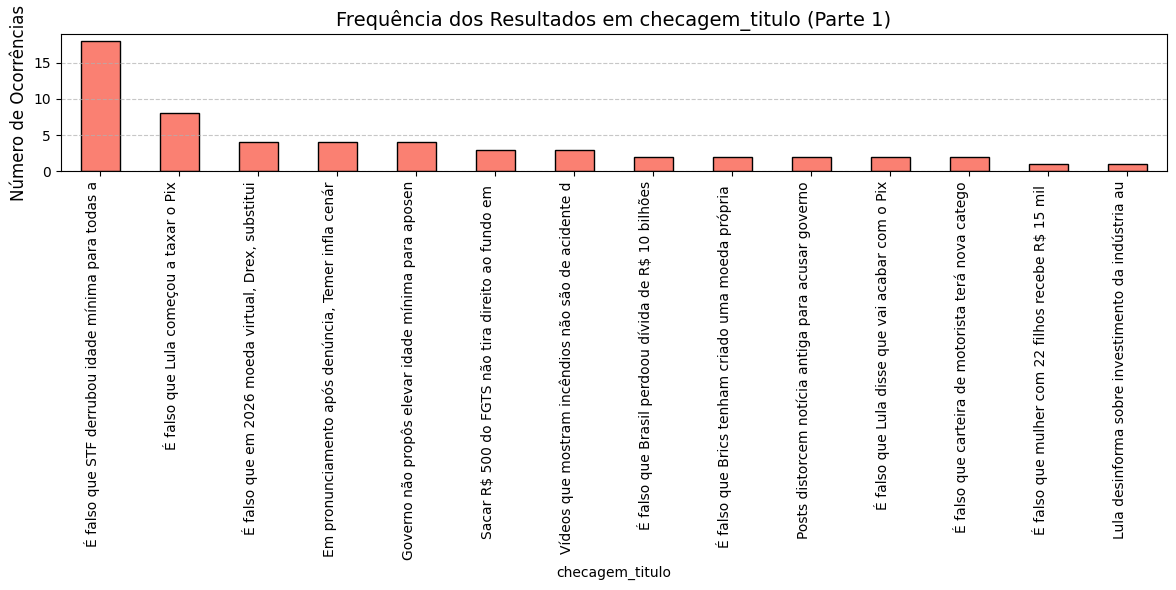

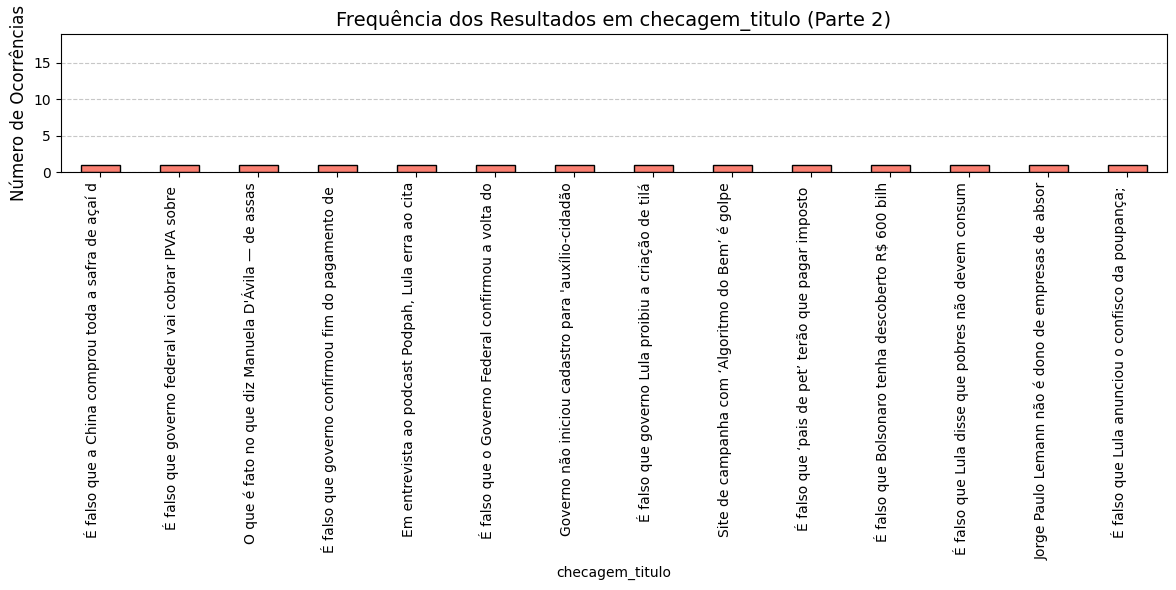

In [ ]:
import matplotlib.pyplot as plt

def plotar_frequencias_mesma_escala(dataframe):
    contagem = dataframe['checagem_titulo'].astype(str).str[:50].value_counts()

    y_max = contagem.max() * 1.05

    meio = len(contagem) // 2

    parte1 = contagem.iloc[:meio]
    parte2 = contagem.iloc[meio:]


    plt.figure(figsize=(12, 6))
    parte1.plot(kind='bar', color='salmon', edgecolor='black')
    plt.title('Frequência dos Resultados em checagem_titulo (Parte 1)', fontsize=14)
    plt.ylabel('Número de Ocorrências', fontsize=12)
    plt.ylim(0, y_max)
    plt.xticks(rotation=90, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 6))
    parte2.plot(kind='bar', color='salmon', edgecolor='black')
    plt.title('Frequência dos Resultados em checagem_titulo (Parte 2)', fontsize=14)
    plt.ylabel('Número de Ocorrências', fontsize=12)
    plt.ylim(0, y_max)
    plt.xticks(rotation=90, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()

plotar_frequencias_mesma_escala(df)

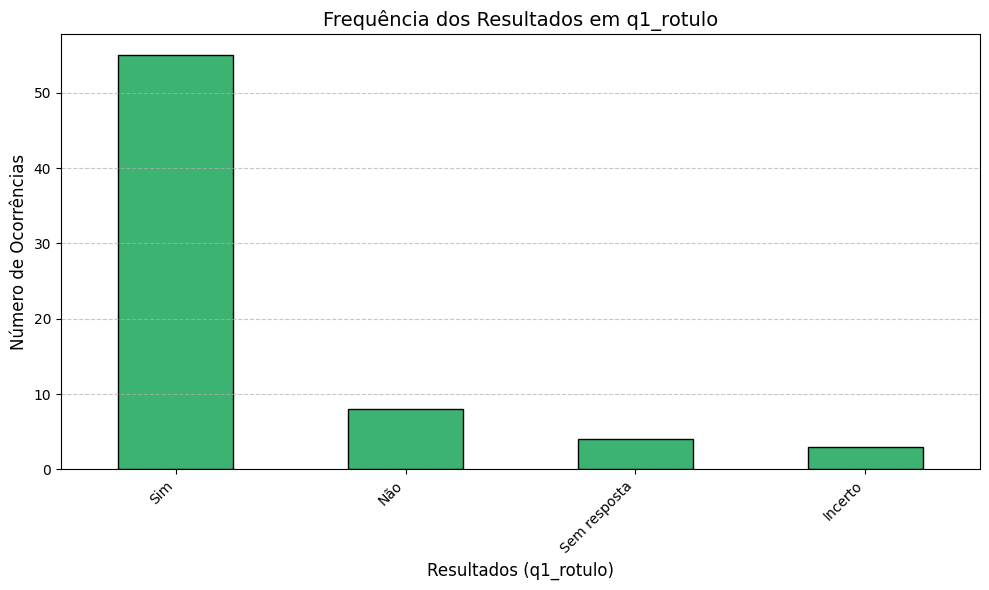

In [ ]:
import matplotlib.pyplot as plt

def plotar_frequencia_q1(dataframe):
    contagem = dataframe['q1_rotulo'].value_counts()

    plt.figure(figsize=(10, 6))
    contagem.plot(kind='bar', color='mediumseagreen', edgecolor='black')

    plt.title('Frequência dos Resultados em q1_rotulo', fontsize=14)
    plt.xlabel('Resultados (q1_rotulo)', fontsize=12)
    plt.ylabel('Número de Ocorrências', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.grid(axis='y', linestyle='--', alpha=0.7)

    plt.tight_layout()
    plt.show()

plotar_frequencia_q1(df)

# Deletar

In [ ]:
def delete_tst(root, word, depth=0):
    if not root:
        return None

    if word[depth] < root.data:
        root.left = delete_tst(root.left, word, depth)
    elif word[depth] > root.data:
        root.right = delete_tst(root.right, word, depth)
    else:
        if depth + 1 < len(word):
            root.eq = delete_tst(root.eq, word, depth + 1)
        else:
            if root.isEndOfString:
                root.isEndOfString = False
                root.metadata = None

        if not root.isEndOfString and not root.left and not root.eq and not root.right:
            return None

    return root

num_execucoes = 10
tempos_delecao = []

for _ in range(num_execucoes):
    titulo_para_remover = df['video_titulo'].iloc[0]
    v_struct = VideoNodeData(
        video_url=df['video_url'].iloc[0],
        checagem_titulo=df['checagem_titulo'].iloc[0],
        checagem_url=df['checagem_url'].iloc[0],
        q1_rotulo=df['q1_rotulo'].iloc[0],
        q2_rotulo=df['q2_rotulo'].iloc[0],
        video_indisponivel=df['video_indisponivel'].iloc[0],
    )
    root = insert_with_metadata(root, titulo_para_remover, v_struct)

    inicio = time.perf_counter()
    root = delete_tst(root, titulo_para_remover)
    fim = time.perf_counter()

    tempos_delecao.append(fim - inicio)

tempo_medio_delecao = sum(tempos_delecao) / num_execucoes

print(f"Tentando remover o título: '{titulo_para_remover}'")
print("-> Sucesso! O título foi removido da árvore TST.")
print("\n" + "="*50)


Tentando remover o título: 'O Lula não vai acabar com o pix'
-> Sucesso! O título foi removido da árvore TST.



# Comparação de tempos

In [ ]:
print("=" * 75)
print(f"{'Operação':<35} | {'Árvore B (s)':<17} | {'TST (s)':<15}")
print("=" * 75)
print(f"{'a) Inserção de todos os elementos':<35} | {tempo_a:<17.6f} | {tempo_medio:<15.6f}")
print(f"{'b) Busca de elemento/tema':<35} | {tempo_b:<17.6f} | {tempo_medio_busca:<15.6f}")
print(f"{'c) Remoção de vídeo específico':<35} | {tempo_c:<17.6f} | {tempo_medio_delecao:<15.6f}")
print(f"{'d) Impressão Fake News':<35} | {tempo_d:<17.6f} | {media_diss:<15.6f}")
print(f"{'e) Impressão Verdadeira':<35} | {tempo_e:<17.6f} | {media_nao_diss:<15.6f}")
print("=" * 75)

Operação                            | Árvore B (s)      | TST (s)        
a) Inserção de todos os elementos   | 0.005270          | 0.008548       
b) Busca de elemento/tema           | 0.000431          | 0.001233       
c) Remoção de vídeo específico      | 0.000171          | 0.000018       
d) Impressão Fake News              | 0.000398          | 0.001066       
e) Impressão Verdadeira             | 0.000450          | 0.000988       


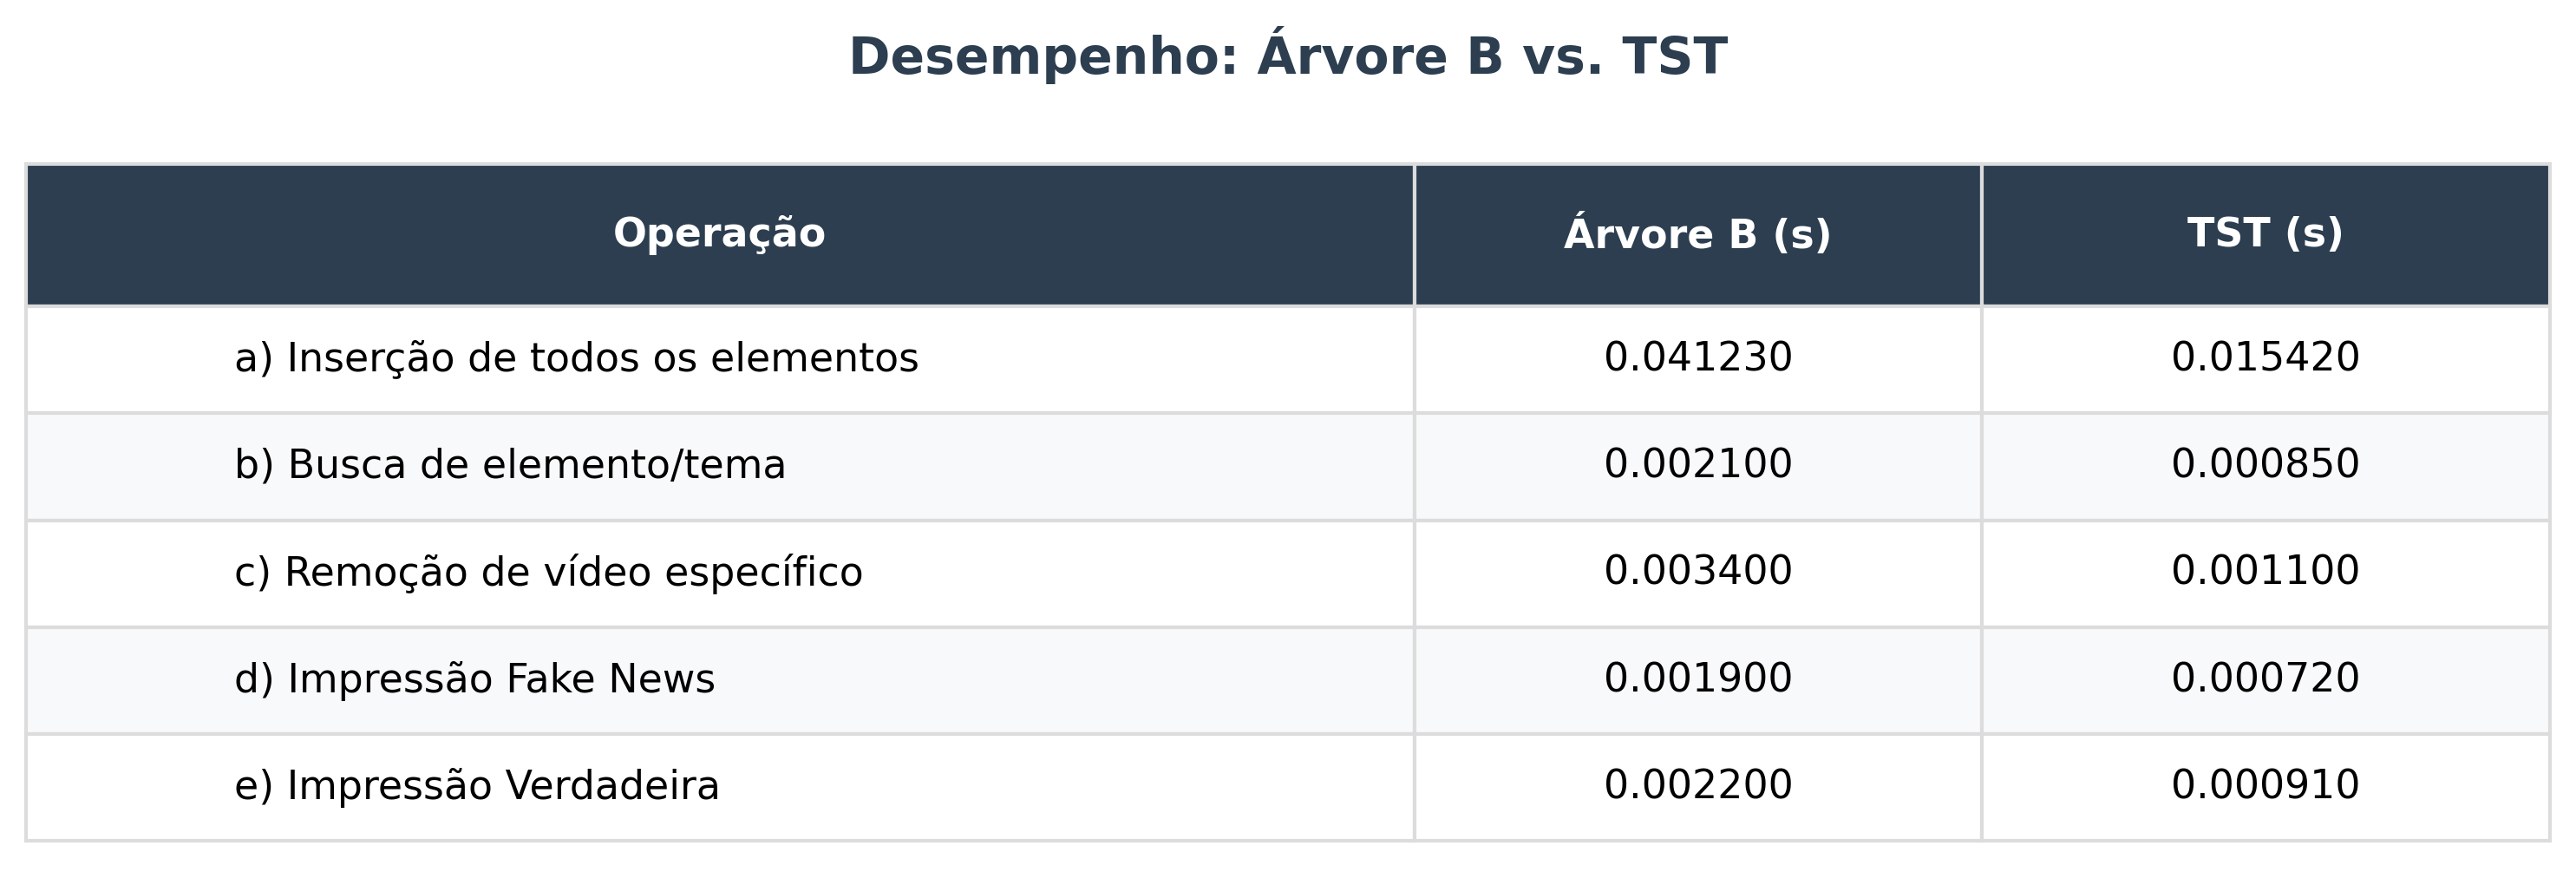

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

operacoes = [
    "a) Inserção de todos os elementos",
    "b) Busca de elemento/tema",
    "c) Remoção de vídeo específico",
    "d) Impressão Fake News",
    "e) Impressão Verdadeira"
]

tempo_a, tempo_medio = 0.041230, 0.015420
tempo_b, tempo_medio_busca = 0.002100, 0.000850
tempo_c, tempo_medio_delecao = 0.003400, 0.001100
tempo_d, media_diss = 0.001900, 0.000720
tempo_e, media_nao_diss = 0.002200, 0.000910

col_arvore_b = [
    f"{tempo_a:.6f}",
    f"{tempo_b:.6f}",
    f"{tempo_c:.6f}",
    f"{tempo_d:.6f}",
    f"{tempo_e:.6f}"
]

col_tst = [
    f"{tempo_medio:.6f}",
    f"{tempo_medio_busca:.6f}",
    f"{tempo_medio_delecao:.6f}",
    f"{media_diss:.6f}",
    f"{media_nao_diss:.6f}"
]

dados_tabela = []
for op, b, tst in zip(operacoes, col_arvore_b, col_tst):
    dados_tabela.append([op, b, tst])

cabecalho = ["Operação", "Árvore B (s)", "TST (s)"]

fig, ax = plt.subplots(figsize=(10, 3.5), dpi=300)
ax.axis('off')

tabela = ax.table(
    cellText=dados_tabela,
    colLabels=cabecalho,
    loc='center',
    cellLoc='center'
)

tabela.auto_set_font_size(False)
tabela.set_fontsize(11)

larguras_colunas = [0.55, 0.225, 0.225]
for i, largura in enumerate(larguras_colunas):
    for j in range(len(dados_tabela) + 1):
        celula = tabela[j, i]
        celula.set_width(largura)

for (linha, coluna), celula in tabela.get_celld().items():
    celula.set_edgecolor('#dcdcdc')
    if linha == 0:
        celula.set_facecolor('#2c3e50')
        celula.set_text_props(weight='bold', color='white')
        celula.set_height(0.2)
    else:
        celula.set_height(0.15)

        if coluna == 0:
            celula.set_text_props(ha='left')
            celula.PAD = 0.15
        if linha % 2 == 0:
            celula.set_facecolor('#f8f9fa')
        else:
            celula.set_facecolor('#ffffff')

plt.title("Desempenho: Árvore B vs. TST", fontsize=14, weight='bold', pad=20, color='#2c3e50')
plt.tight_layout()

plt.savefig("benchmark_arvore_b_tst.png", bbox_inches='tight', dpi=300)
plt.show()